In [1]:
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt, seaborn as sns
from ss_utils import *
df = load_data(".")   # the folder with train.csv and test.csv

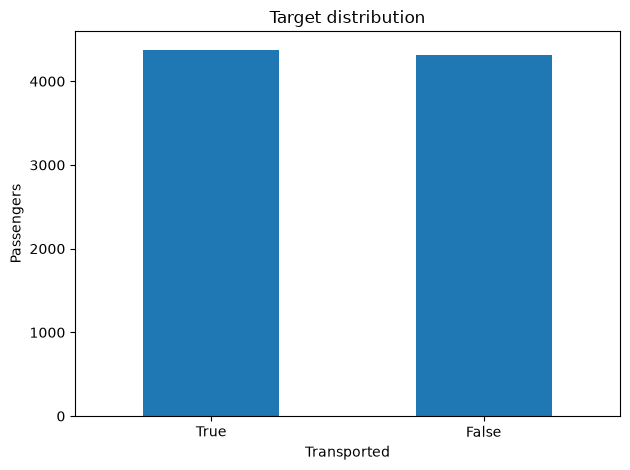

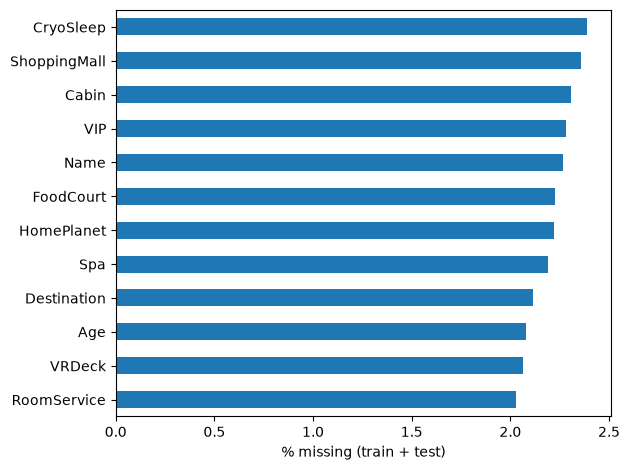

rows with >=1 missing: 23.8 %


In [2]:
import os; os.makedirs("figures", exist_ok=True)
tr = df[df.split == "train"].copy()

ax = tr["Transported"].map({1: "True", 0: "False"}).value_counts().plot.bar(rot=0)
ax.set_ylabel("Passengers"); ax.set_title("Target distribution")
plt.tight_layout(); plt.savefig("figures/fig_target.png", dpi=200); plt.show()

raw = ["HomePlanet","CryoSleep","Cabin","Destination","Age","VIP"] + SPEND + ["Name"]
ax = (df[raw].isna().mean().sort_values() * 100).plot.barh()
ax.set_xlabel("% missing (train + test)")
plt.tight_layout(); plt.savefig("figures/fig_missing.png", dpi=200); plt.show()
print("rows with >=1 missing:", round(df[raw].isna().any(axis=1).mean()*100, 1), "%")

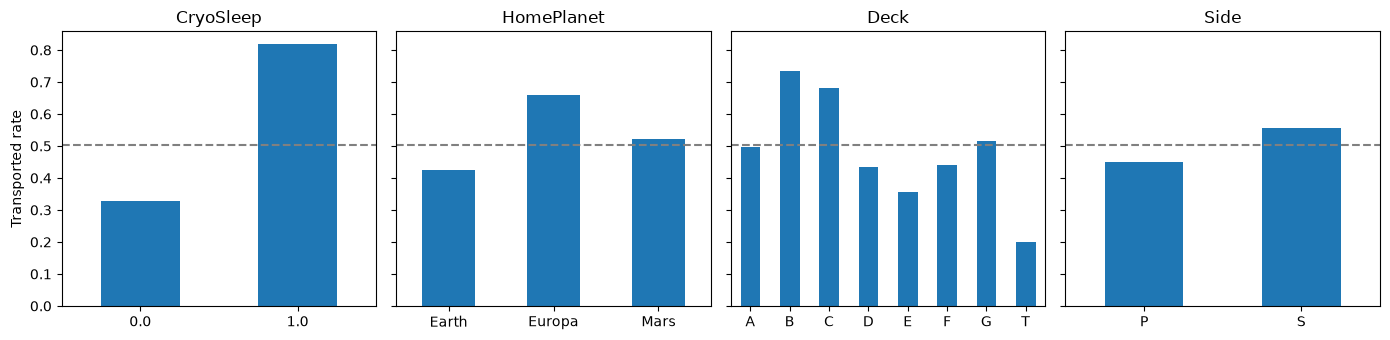

CryoSleep,0.0,1.0
mean,0.329,0.818
size,5439.000,3037.000


HomePlanet,Earth,Europa,Mars
mean,0.424,0.659,0.523
size,4602.000,2131.000,1759.000


Deck,A,B,C,D,E,F,G,T
mean,0.496,0.734,0.68,0.433,0.357,0.44,0.516,0.2
size,256.000,779.000,747.00,478.000,876.000,2794.00,2559.000,5.0


Side,P,S
mean,0.451,0.555
size,4206.000,4288.000


Destination,55 Cancri e,PSO J318.5-22,TRAPPIST-1e
mean,0.61,0.504,0.471
size,1800.00,796.000,5915.000


VIP,0.0,1.0
mean,0.506,0.382
size,8291.000,199.000


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, col in zip(axes, ["CryoSleep", "HomePlanet", "Deck", "Side"]):
    tr.groupby(col)["Transported"].mean().plot.bar(ax=ax, rot=0)
    ax.axhline(tr["Transported"].mean(), ls="--", c="grey"); ax.set_title(col); ax.set_xlabel("")
axes[0].set_ylabel("Transported rate")
plt.tight_layout(); plt.savefig("figures/fig_rate_by_cat.png", dpi=200); plt.show()
for col in ["CryoSleep", "HomePlanet", "Deck", "Side", "Destination", "VIP"]:
    display(tr.groupby(col)["Transported"].agg(["mean", "size"]).round(3).T)

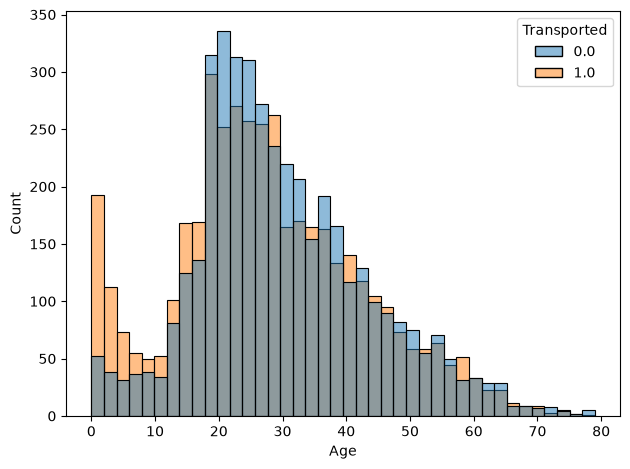

AgeBand
(-1, 12]     0.700
(12, 17]     0.553
(17, 25]     0.458
(25, 40]     0.480
(40, 200]    0.492
Name: Transported, dtype: float64

In [4]:
sns.histplot(data=tr, x="Age", hue="Transported", bins=40)
plt.tight_layout(); plt.savefig("figures/fig_age.png", dpi=200); plt.show()
tr["AgeBand"] = pd.cut(tr["Age"], [-1, 12, 17, 25, 40, 200])
tr.groupby("AgeBand", observed=True)["Transported"].mean().round(3)

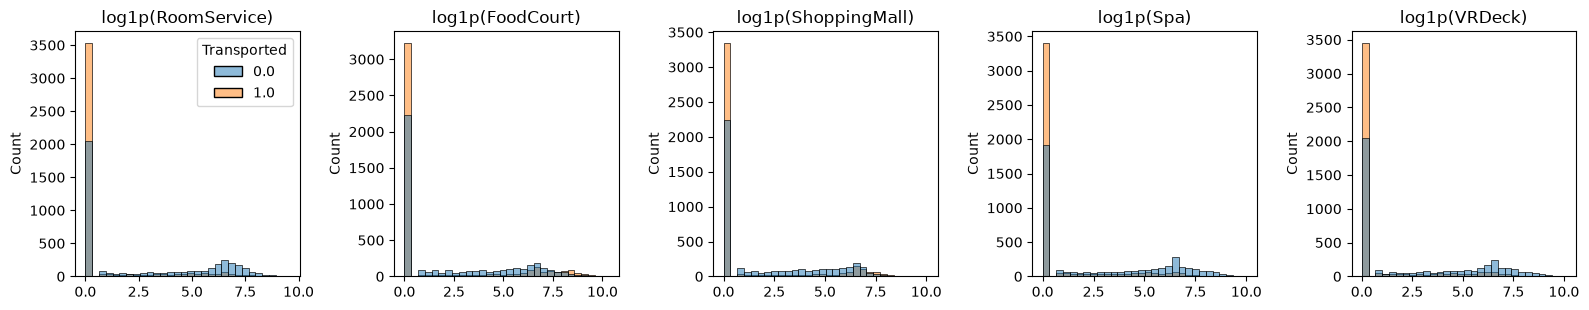

zero-spend share: 0.42
rate by spent>0: {False: 0.786, True: 0.299}
max spend while in CryoSleep: {'RoomService': 0.0, 'FoodCourt': 0.0, 'ShoppingMall': 0.0, 'Spa': 0.0, 'VRDeck': 0.0}


In [5]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, c in zip(axes, SPEND):
    sns.histplot(x=np.log1p(tr[c]), hue=tr["Transported"], bins=30, ax=ax, legend=(c == SPEND[0]))
    ax.set_title(f"log1p({c})"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("figures/fig_spend.png", dpi=200); plt.show()
spent = tr[SPEND].fillna(0).sum(axis=1) > 0
print("zero-spend share:", round(1 - spent.mean(), 3))
print("rate by spent>0:", tr.groupby(spent)["Transported"].mean().round(3).to_dict())
print("max spend while in CryoSleep:", tr.loc[tr.CryoSleep == 1, SPEND].max().to_dict())

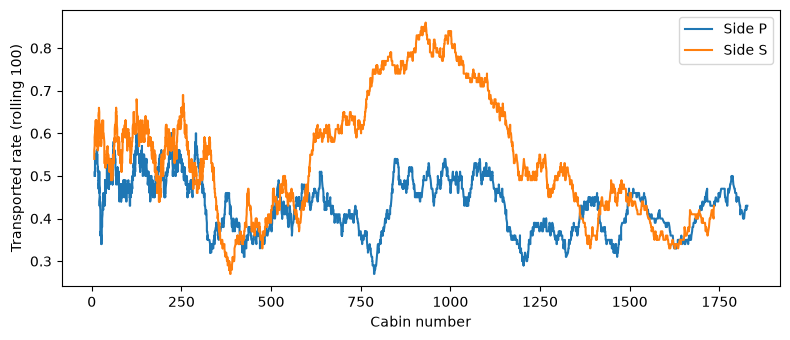

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for side, grp in tr.dropna(subset=["CabinNum"]).sort_values("CabinNum").groupby("Side"):
    ax.plot(grp["CabinNum"], grp["Transported"].rolling(100, center=True).mean(), label=f"Side {side}")
ax.set_xlabel("Cabin number"); ax.set_ylabel("Transported rate (rolling 100)"); ax.legend()
plt.tight_layout(); plt.savefig("figures/fig_cabin_num.png", dpi=200); plt.show()

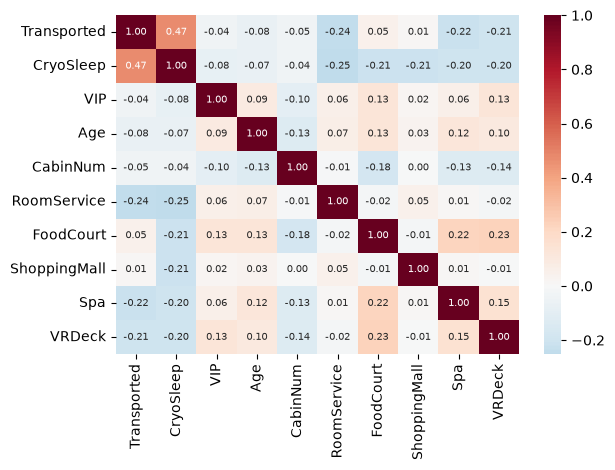

multi-member groups: 2135
share with one HomePlanet: 1.0
multi-member train groups where everyone shares the outcome: 0.436


Deck  HomePlanet
A     Europa        1.00
B     Europa        1.00
C     Europa        1.00
D     Mars          0.58
      Europa        0.42
E     Earth         0.45
      Mars          0.39
      Europa        0.15
F     Earth         0.59
      Mars          0.41
G     Earth         1.00
T     Europa        1.00
Name: proportion, dtype: float64

In [7]:
num = tr[["Transported","CryoSleep","VIP","Age","CabinNum"] + SPEND]
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.tight_layout(); plt.savefig("figures/fig_corr.png", dpi=200); plt.show()

gs = df.groupby("GroupId")
multi = gs.size() > 1
print("multi-member groups:", multi.sum())
print("share with one HomePlanet:", (gs["HomePlanet"].nunique()[multi] <= 1).mean().round(3))
shared = tr.groupby("GroupId").filter(lambda x: len(x) > 1).groupby("GroupId")["Transported"].nunique().eq(1).mean()
print("multi-member train groups where everyone shares the outcome:", round(shared, 3))
df.groupby("Deck")["HomePlanet"].value_counts(normalize=True).round(2)